# TOFFEE Light Curve Prep: `flatten()`, Breaks, and Masking

Notebook 1 called `flatten()` once and moved on. This notebook explains what it actually does, argument by argument, and the two masking functions underneath it: `break_finder` and `light_curve_mask`. It switches to a new example target, AU Mic (TIC 441420236, sector 27), whose strong ~4.836-day spot-modulation signal is exactly the kind of periodic structure `flatten()`'s `periodogram` argument exists to remove.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import toffee

## 1. Reload the example light curve

A different target from notebook 1: AU Mic, a young, rapidly-rotating star with a well-known ~4.836-day rotation period from two starspot-dominated active regions. Same two data-cleaning steps as notebook 1 (converting out of `MaskedNDArray`, dropping non-finite cadences); see notebook 1 for why each is needed.

In [2]:
################ TUTORIAL TARGET ################
#change these two values to try a different star/sector
TIC_ID = 441420236
SECTOR = 27

import lightkurve as lk

search_result = lk.search_lightcurve(f'TIC {TIC_ID}', mission = 'TESS', author = 'SPOC',
                                     exptime = 120, sector = SECTOR)
lc = search_result.download()

time = np.asarray(lc.time.value, dtype = float)
flux = np.asarray(lc.flux.value, dtype = float)
flux_err = np.asarray(lc.flux_err.value, dtype = float)

finite = np.isfinite(time) & np.isfinite(flux) & np.isfinite(flux_err)
time, flux, flux_err = time[finite], flux[finite], flux_err[finite]
print(f'{len(time)} cadences after dropping non-finite values')

16767 cadences after dropping non-finite values


## 2. `flatten()`'s full signature

```python
def flatten(lc_t, raw_lc, raw_lc_errs, plot_results=False, short_window=None, periodogram=None):
```

| Argument | Type | Default | Meaning |
|---|---|---|---|
| `lc_t` | array | required | Time coordinates, in days (TESS BJD - 2,457,000, if the data came from `lightkurve`) |
| `raw_lc` | array | required | Flux values, same length as `lc_t`. Any units are fine: `flatten()` normalizes per orbit, so you don't need to normalize first |
| `raw_lc_errs` | array | required | Flux uncertainties, same length and units as `raw_lc` |
| `plot_results` | bool | `False` | If `True`, shows a diagnostic plot after each detrending stage as it runs |
| `short_window` | float or `None` | `None` | Window length, in days, for an additional `wotan` flatten pass on top of the per-orbit quadratic fit. `None` skips this stage entirely |
| `periodogram` | `[float, float]` or `None` | `None` | A frequency range, in cycles/day, to search for leftover periodic (sinusoidal) signal and remove it. `None` skips this stage entirely |

## 3. What `flatten()` actually does, stage by stage

1. **Always runs:** fit and divide out a quadratic trend, separately for each TESS orbit. This result is called `lc_quad` below.
2. **If `short_window` is set:** run `wotan.flatten()` on top of that, using `short_window` as the rolling window length. This result is called `lc_wotan`.
3. **If `periodogram` is set:** search the given frequency range for a significant periodic signal (via Lomb-Scargle) and, if one is found, divide it out too. This result is called `lc_flat`.

Every `lc_*` result is a single `numpy` array of shape `(3, N)`, not three separate arrays; always unpack it by index:

| Index | Contents |
|---|---|
| `lc_*[0]` | Flattened flux |
| `lc_*[1]` | Flattened flux uncertainties |
| `lc_*[2]` | The trend that was divided out to get `lc_*[0]` |

## 4. The return value depends on which stages you ran

This is the part that trips people up: **the number of return values changes with your arguments**, and nothing about the values themselves tells you how many to expect; you have to know which arguments you passed.

| Call | Returns |
|---|---|
| `flatten(t, f, e)` | `(orbit_time, lc_quad, periodic)`: 3 values |
| `flatten(t, f, e, short_window=0.25)` | `(orbit_time, lc_quad, lc_wotan, periodic)`: 4 values |
| `flatten(t, f, e, short_window=0.25, periodogram=[0.1, 10])` | `(orbit_time, lc_quad, lc_wotan, lc_flat, periodic)`: 5 values |

`orbit_time` is always first, `periodic` (a bool: was a significant periodic signal found and removed?) is always last. Let's see all three.

In [3]:
#branch 1: no short_window, no periodogram -- only the quadratic-detrended stage exists
orbit_time, lc_quad, periodic = toffee.flatten(time, flux, flux_err)
print(f'3 return values. lc_quad shape: {lc_quad.shape}. periodic: {periodic}')

3 return values. lc_quad shape: (3, 16755). periodic: False


**Figure: the quadratic-detrending stage.** Top panel is the raw flux (reconstructed as `lc_quad[0] * lc_quad[2]`, since `flatten()` only keeps cadences inside a defined TESS orbit, so this is the raw flux realigned to `orbit_time`) with the fitted quadratic trend in orange. Notice it's fit *separately per orbit*, so it resets at the gap. The double-humped wave riding on top of that trend is AU Mic's own rotation, not an artifact: a smooth per-orbit quadratic can't track a ~4.8-day wiggle, so it survives untouched into the bottom panel, the result of dividing that trend out.

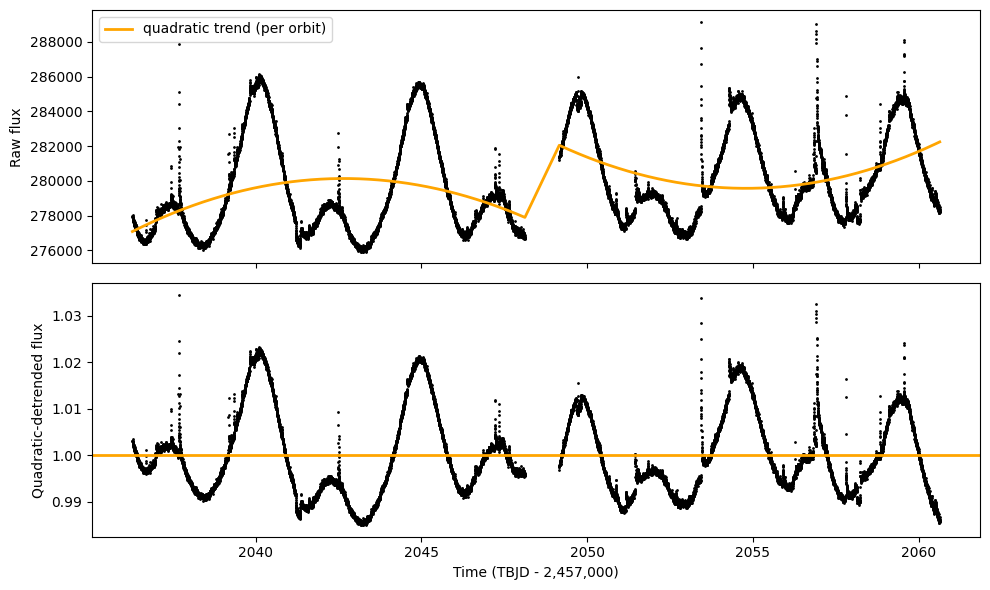

In [4]:
#reconstruct the raw (orbit-aligned) flux from lc_quad: since lc_quad[0] = raw_flux / trend,
#raw_flux = lc_quad[0] * lc_quad[2]
raw_flux_aligned = lc_quad[0] * lc_quad[2]

fig, axs = plt.subplots(2, 1, figsize = (10, 6), sharex = True)
axs[0].plot(orbit_time, raw_flux_aligned, '.', color = 'black', markersize = 2)
axs[0].plot(orbit_time, lc_quad[2], color = 'orange', linewidth = 2, label = 'quadratic trend (per orbit)')
axs[0].set_ylabel('Raw flux')
axs[0].legend()
axs[1].plot(orbit_time, lc_quad[0], '.', color = 'black', markersize = 2)
axs[1].axhline(1.0, color = 'orange', linewidth = 2)
axs[1].set_ylabel('Quadratic-detrended flux')
axs[1].set_xlabel('Time (TBJD - 2,457,000)')
plt.tight_layout()
plt.show()

In [5]:
#branch 2: short_window set, periodogram not -- adds the wotan-flattened stage
orbit_time, lc_quad, lc_wotan, periodic = toffee.flatten(time, flux, flux_err, short_window = 0.25)
print(f'4 return values. lc_wotan shape: {lc_wotan.shape}. periodic: {periodic}')

4 return values. lc_wotan shape: (3, 16755). periodic: False


**Figure: the wotan stage.** Top panel is the quadratic-detrended flux from above (its own input this time), with the `wotan` rolling-window trend in orange. Bottom panel is the result of dividing that out too: this is `lc_wotan[0]`, the flux `detect_flares()` actually runs on. With `short_window=0.25` much shorter than AU Mic's ~4.8-day rotation, `wotan`'s job is to erase multi-day structure, so it tracks and removes nearly all of that modulation here, leaving mostly flares and small residual noise.

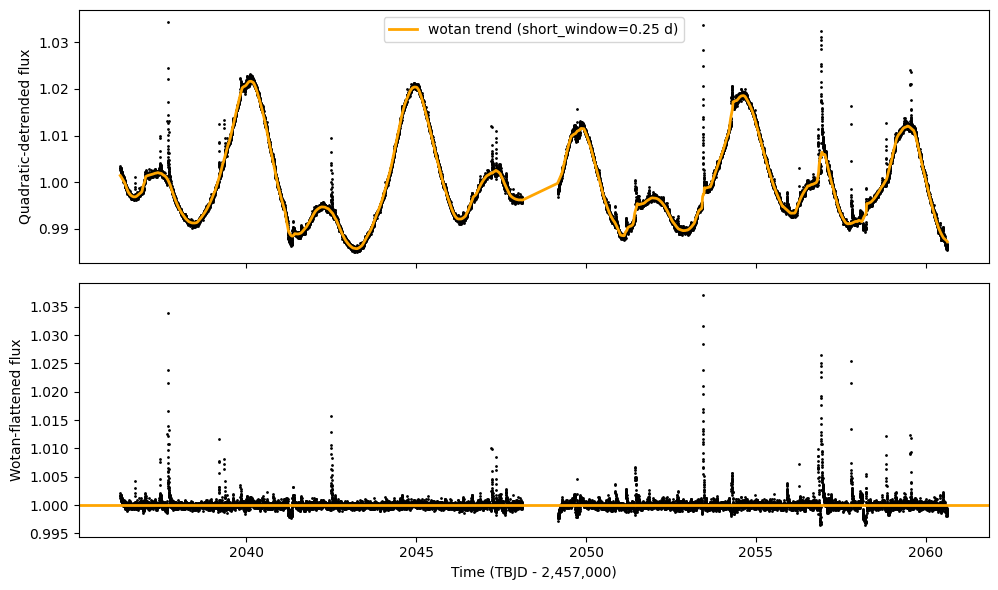

In [6]:
fig, axs = plt.subplots(2, 1, figsize = (10, 6), sharex = True)
axs[0].plot(orbit_time, lc_quad[0], '.', color = 'black', markersize = 2)
axs[0].plot(orbit_time, lc_wotan[2], color = 'orange', linewidth = 2, label = 'wotan trend (short_window=0.25 d)')
axs[0].set_ylabel('Quadratic-detrended flux')
axs[0].legend()
axs[1].plot(orbit_time, lc_wotan[0], '.', color = 'black', markersize = 2)
axs[1].axhline(1.0, color = 'orange', linewidth = 2)
axs[1].set_ylabel('Wotan-flattened flux')
axs[1].set_xlabel('Time (TBJD - 2,457,000)')
plt.tight_layout()
plt.show()

## 5. Adding `periodogram`

With `periodogram` set too, `flatten()` searches for and removes periodic signal, and returns a fifth value, `lc_flat`. Let's look at the Lomb-Scargle periodogram it searches first (the same computation `flatten()` runs internally, over the same frequency range) to see what peak it's reacting to, then measure what the correction actually changes, compared to the plain wotan-flattened flux from branch 2.

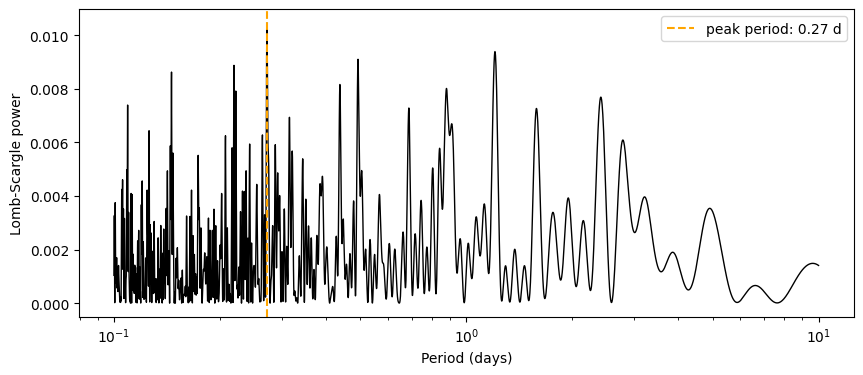

false alarm probability at the peak: 2.49e-33


In [7]:
from astropy.timeseries import LombScargle

#the same Lomb-Scargle search flatten() runs internally when periodogram=[0.1, 10] --
#frequency is in cycles/day, so period (in days) is 1/frequency
frequency = np.linspace(0.1, 10, 100000)
ls = LombScargle(orbit_time, lc_wotan[0], lc_wotan[1])
power = ls.power(frequency)
peak_freq = frequency[np.argmax(power)]

fig, ax = plt.subplots(figsize = (10, 4))
ax.plot(1 / frequency, power, color = 'black', linewidth = 1)
ax.axvline(1 / peak_freq, color = 'orange', linestyle = '--', label = f'peak period: {1/peak_freq:.2f} d')
ax.set_xscale('log')
ax.set_xlabel('Period (days)')
ax.set_ylabel('Lomb-Scargle power')
ax.legend()
plt.show()
print(f'false alarm probability at the peak: {ls.false_alarm_probability(power.max()):.2e}')

The peak found here, ~0.27 days, is not AU Mic's actual ~4.836-day rotation period. The wotan pass above already removed nearly all of that signal: `short_window=0.25` is small enough, relative to a ~4.8-day period, that `wotan` tracks and divides out almost the whole modulation (see the wotan-stage figure above). What's left in `lc_wotan` is a smaller, shorter-period residual, and that's exactly what `periodogram` is for: catching whatever periodic signal remains, regardless of its origin, and removing it too.

In [8]:
#branch 3: both short_window and periodogram set -- adds the periodogram-corrected stage
orbit_time, lc_quad, lc_wotan, lc_flat, periodic = toffee.flatten(time, flux, flux_err,
                                                                  short_window = 0.25,
                                                                  periodogram = [0.1, 10])
print(f'5 return values. periodic: {periodic}')

#compare the periodogram-corrected flux against the plain wotan-flattened flux to see
#how much the correction actually changed
correction = np.abs(lc_wotan[0] - lc_flat[0])
print(f'median flux change from the correction: {np.median(correction):.4f}')
print(f'largest flux change: {correction.max():.4f}')

5 return values. periodic: True
median flux change from the correction: 0.0002
largest flux change: 0.0094


**Figure: the periodogram-correction stage.** Top panel overlays the wotan-flattened flux with the local median-filtered trend that gets divided out at the detected period (orange). Bottom panel is the result: `lc_flat[0]`. Compare it against the wotan-flattened panel two figures up: this is the change the correction actually made.

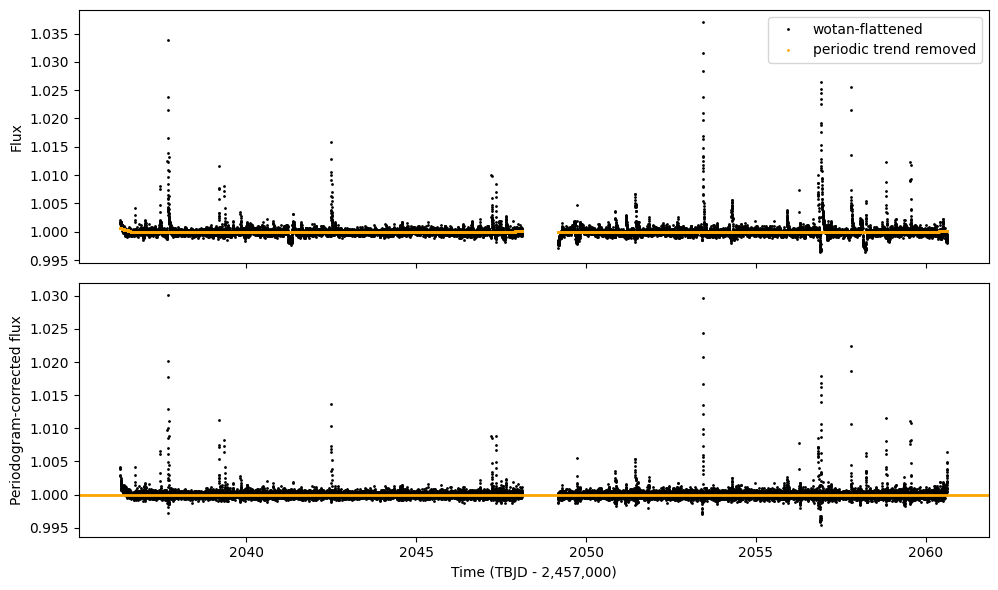

In [9]:
fig, axs = plt.subplots(2, 1, figsize = (10, 6), sharex = True)
axs[0].plot(orbit_time, lc_wotan[0], '.', color = 'black', markersize = 2, label = 'wotan-flattened')
axs[0].plot(orbit_time, lc_flat[2], '.', color = 'orange', markersize = 2, label = 'periodic trend removed')
axs[0].set_ylabel('Flux')
axs[0].legend()
axs[1].plot(orbit_time, lc_flat[0], '.', color = 'black', markersize = 2)
axs[1].axhline(1.0, color = 'orange', linewidth = 2)
axs[1].set_ylabel('Periodogram-corrected flux')
axs[1].set_xlabel('Time (TBJD - 2,457,000)')
plt.tight_layout()
plt.show()

**Don't reuse `lc_flat` to measure the period it just removed.** `periodogram` actively searches for and divides out whatever periodic signal it finds in that frequency range. That's useful for stripping stellar rotation modulation out of the way *before* flare detection, but it means `lc_flat` is the wrong input if you're separately trying to *measure* a rotation period, since most of that signal is now gone by construction. `lc_wotan` isn't safe either: `short_window`'s whole job is to erase multi-day structure, so it strips out a real rotation period along with everything else. `lc_quad` is the one that still shows AU Mic's ~4.8-day signal cleanly here. Skip `periodogram`, and use `lc_quad` for anything that needs the periodic signal to survive.

## 6. `break_finder`: locating gaps

```python
def break_finder(time, flux, min_break=0.25):
```

| Argument | Type | Default | Meaning |
|---|---|---|---|
| `time` | array | required | Time coordinates, in days |
| `flux` | array | required | Flux values, same length as `time`: only used to know how many cadences there are; `break_finder` looks for gaps in `time`, not features in `flux` |
| `min_break` | float | `0.25` | Minimum gap size, in days, to count as a break (e.g. a TESS momentum dump or the downlink gap between orbits) |

Returns a DataFrame, one row per break found:

| Column | Meaning |
|---|---|
| `Break_Index` | Index of the last cadence before the gap |
| `Break_Start_Time` | Time of that last cadence |
| `Break_End_Time` | Time of the first cadence after the gap |

In [10]:
breaks = toffee.break_finder(orbit_time, lc_wotan[0], min_break = 0.25)
breaks

,Break_Index,Break_Start_Time,Break_End_Time
0,8506,2048.124606,2049.159345


This target has one break: the downlink gap between the sector's two TESS orbits.

## 7. `light_curve_mask`: clipping around those gaps

```python
def light_curve_mask(time, flux, min_break=0.25, clip_breaks=200):
```

| Argument | Type | Default | Meaning |
|---|---|---|---|
| `time` | array | required | Same as `break_finder`'s |
| `flux` | array | required | Same as `break_finder`'s |
| `min_break` | float | `0.25` | Same meaning as `break_finder`'s |
| `clip_breaks` | int | `200` | Number of cadences to mask out on *each side* of every break found (200 cadences is 400 minutes at TESS's 2-minute cadence) |

Returns a boolean array, same length as `time`: `True` for a cadence to keep, `False` to drop.

**Why clip at all?** Data right next to a gap (a momentum dump, a downlink) is more likely to carry instrumental artifacts that look like flares but aren't. Trimming a buffer on each side reduces false positives, at the cost of a small amount of real data (it also clips `clip_breaks` cadences off the very start and end of the light curve, for the same reason).

In [11]:
mask = toffee.light_curve_mask(orbit_time, lc_wotan[0], min_break = 0.25, clip_breaks = 200)
print(f'{(~mask).sum()} of {len(mask)} cadences clipped')

800 of 16755 cadences clipped


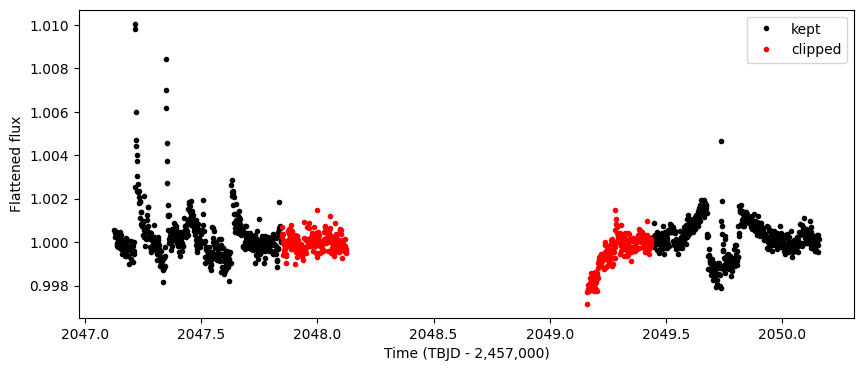

In [12]:
#zoom in on the break found above and show which cadences get kept vs clipped
zoom = ((orbit_time > breaks['Break_Start_Time'].iloc[0] - 1) &
       (orbit_time < breaks['Break_End_Time'].iloc[0] + 1))

fig, ax = plt.subplots(figsize = (10, 4))
ax.plot(orbit_time[zoom & mask], lc_wotan[0][zoom & mask], '.', color = 'black', label = 'kept')
ax.plot(orbit_time[zoom & ~mask], lc_wotan[0][zoom & ~mask], '.', color = 'red', label = 'clipped')
ax.set_xlabel('Time (TBJD - 2,457,000)')
ax.set_ylabel('Flattened flux')
ax.legend()
plt.show()

## 8. You usually don't call these two directly

`detect_flares()` already calls `light_curve_mask()` internally, using its own `min_break` and `clip_breaks` arguments (defaults `0.25` and `200`, the same values used above). This notebook exists to explain what those two `detect_flares()` knobs actually do, not to introduce a manual step you need to add to your own workflow.

## Summary

- `flatten()`'s return value has 3, 4, or 5 entries depending on `short_window`/`periodogram`: match your unpacking to the table in section 4.
- Every `lc_*` result is a `(3, N)` array: flux, errors, trend, in that order.
- `periodogram` removes periodic signal: don't reuse its output to measure that same period afterward.
- `short_window` much shorter than a real periodic signal doesn't just fail to remove it: `wotan` tracks and divides out nearly all of it too, as seen above with AU Mic's rotation. Check `lc_quad` if you need that signal to survive.
- `break_finder`/`light_curve_mask` find and clip TESS orbit gaps; `detect_flares()`'s own `min_break`/`clip_breaks` arguments do this for you.

Notebook 3 covers the flare-decay models underneath `detect_flares()`, using the overlapping flare pair from notebook 1's example light curve as a worked example.